In [ ]:

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

tf.keras.utils.set_random_seed(42)

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))
print("Libraries imported successfully!")


TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Libraries imported successfully!


In [ ]:

from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/CIFAR10_Final_Project"
os.makedirs(PROJECT_DIR, exist_ok=True)

MODEL_PATH = os.path.join(
    PROJECT_DIR,
    "best_cifar10_model.keras"
)

print("Google Drive connected!")
print("Model path:", MODEL_PATH)


Mounted at /content/drive
Google Drive connected!
Model path: /content/drive/MyDrive/CIFAR10_Final_Project/best_cifar10_model.keras


In [6]:

!pip -q install datasets

from datasets import load_dataset

dataset = load_dataset("uoft-cs/cifar10")

print(dataset)


README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['img', 'label'],
        num_rows: 50000
    })
    test: Dataset({
        features: ['img', 'label'],
        num_rows: 10000
    })
})


In [7]:

import numpy as np

# Convert images into NumPy arrays
x_full = np.array([np.array(img) for img in dataset["train"]["img"]])
y_full = np.array(dataset["train"]["label"])

x_test = np.array([np.array(img) for img in dataset["test"]["img"]])
y_test = np.array(dataset["test"]["label"])

print("Training images:", x_full.shape)
print("Training labels:", y_full.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

print("Dataset conversion completed!")


Training images: (50000, 32, 32, 3)
Training labels: (50000,)
Testing images: (10000, 32, 32, 3)
Testing labels: (10000,)
Dataset conversion completed!


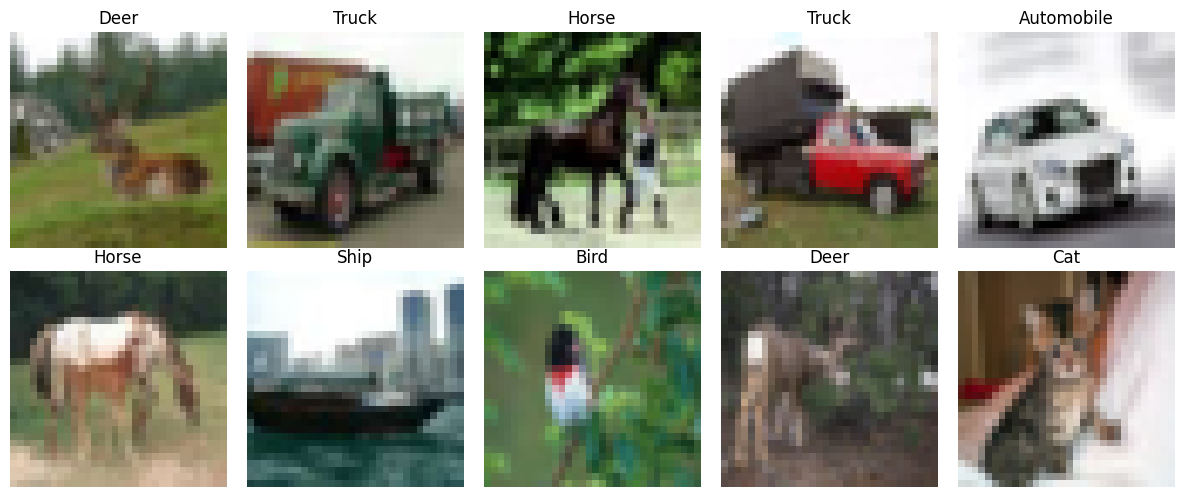

In [8]:

import matplotlib.pyplot as plt
import numpy as np

class_names = [
    "Airplane", "Automobile", "Bird", "Cat",
    "Deer", "Dog", "Frog", "Horse",
    "Ship", "Truck"
]

# Select 10 random images
random_indices = np.random.choice(
    len(x_full), 10, replace=False
)

plt.figure(figsize=(12, 5))

for i, index in enumerate(random_indices):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_full[index])
    plt.title(class_names[int(y_full[index])])
    plt.axis("off")

plt.tight_layout()
plt.show()


In [9]:

from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

# Normalize pixel values to 0-1
x_full = x_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Split into training and validation datasets
x_train, x_val, y_train, y_val = train_test_split(
    x_full,
    y_full,
    test_size=0.2,
    random_state=42,
    stratify=y_full
)

# Convert labels to one-hot encoding
y_train_cat = to_categorical(y_train, 10)
y_val_cat = to_categorical(y_val, 10)
y_test_cat = to_categorical(y_test, 10)

print("Training:", x_train.shape)
print("Validation:", x_val.shape)
print("Testing:", x_test.shape)

print("Preprocessing completed!")


Training: (40000, 32, 32, 3)
Validation: (10000, 32, 32, 3)
Testing: (10000, 32, 32, 3)
Preprocessing completed!


In [10]:

import tensorflow as tf
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(15 / 360),
    layers.RandomTranslation(0.1, 0.1)
], name="data_augmentation")

print("Data augmentation configured successfully!")


Data augmentation configured successfully!


In [11]:

import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

improved_model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    # Data augmentation
    data_augmentation,

    # Block 1 - 32 filters
    layers.Conv2D(32, (3, 3), padding="same",
                  activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), padding="same",
                  activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.2),

    # Block 2 - 64 filters
    layers.Conv2D(64, (3, 3), padding="same",
                  activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), padding="same",
                  activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Block 3 - 128 filters
    layers.Conv2D(128, (3, 3), padding="same",
                  activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(128, (3, 3), padding="same",
                  activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    # Block 4 - 256 filters
    layers.Conv2D(256, (3, 3), padding="same",
                  activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(256, (3, 3), padding="same",
                  activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.35),

    # Classification
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.4),

    # Output - 10 CIFAR-10 classes
    layers.Dense(10, activation="softmax")
])

improved_model.summary()

print("Improved CNN created successfully!")


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 4, 4, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 4, 4, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,442,090 (5.50 MB)

 Trainable params: 1,439,658 (5.49 MB)

 Non-trainable params: 2,432 (9.50 KB)

Improved CNN created successfully!


In [12]:

improved_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN compiled successfully!")


CNN compiled successfully!


In [13]:

from google.colab import drive
import os

drive.mount("/content/drive")

MODEL_DIR = "/content/drive/MyDrive/CIFAR10_Final_Project"
os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_PATH = os.path.join(
    MODEL_DIR, "best_cifar10_model.keras"
)

from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    ReduceLROnPlateau,
    EarlyStopping
)

callbacks = [
    ModelCheckpoint(
        MODEL_PATH,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=0.00001,
        verbose=1
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    )
]

print("Checkpoint configured!")
print("Model will save to:", MODEL_PATH)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoint configured!
Model will save to: /content/drive/MyDrive/CIFAR10_Final_Project/best_cifar10_model.keras


In [14]:

history = improved_model.fit(
    x_train,
    y_train_cat,
    epochs=30,
    batch_size=64,
    validation_data=(x_val, y_val_cat),
    callbacks=callbacks,
    verbose=1
)

print("CNN training completed!")


Epoch 1/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.3037 - loss: 2.1368
Epoch 1: val_accuracy improved from None to 0.51690, saving model to /content/drive/MyDrive/CIFAR10_Final_Project/best_cifar10_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/CIFAR10_Final_Project/best_cifar10_model.keras
625/625 ━━━━━━━━━━━━━━━━━━━━ 32s 31ms/step - accuracy: 0.3784 - loss: 1.8016 - val_accuracy: 0.5169 - val_loss: 1.3871 - learning_rate: 0.0010
Epoch 2/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.5079 - loss: 1.3638
Epoch 2: val_accuracy improved from 0.51690 to 0.60860, saving model to /content/drive/MyDrive/CIFAR10_Final_Project/best_cifar10_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/CIFAR10_Final_Project/best_cifar10_model.keras
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 25ms/step - accuracy: 0.5315 - loss: 1.3064 - val_accuracy: 0.6086 - val_loss: 1.1730 - learning_rate: 0.0010
Epoch 3/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/s

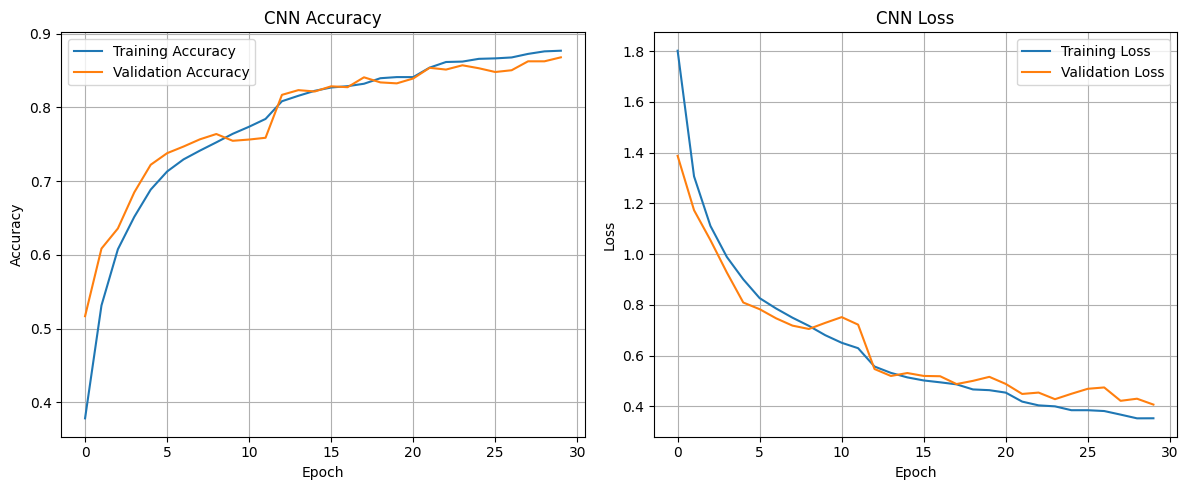

In [15]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"],
         label="Training Accuracy")
plt.plot(history.history["val_accuracy"],
         label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"],
         label="Training Loss")
plt.plot(history.history["val_loss"],
         label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [16]:

# Load the best saved model
best_model = tf.keras.models.load_model(MODEL_PATH)

# Evaluate on unseen test images
test_loss, test_accuracy = best_model.evaluate(
    x_test,
    y_test_cat,
    verbose=1
)

print("----------------------------")
print(f"Final Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Final Test Loss: {test_loss:.4f}")
print("----------------------------")


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8638 - loss: 0.4196
----------------------------
Final Test Accuracy: 86.38%
Final Test Loss: 0.4196
----------------------------


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step


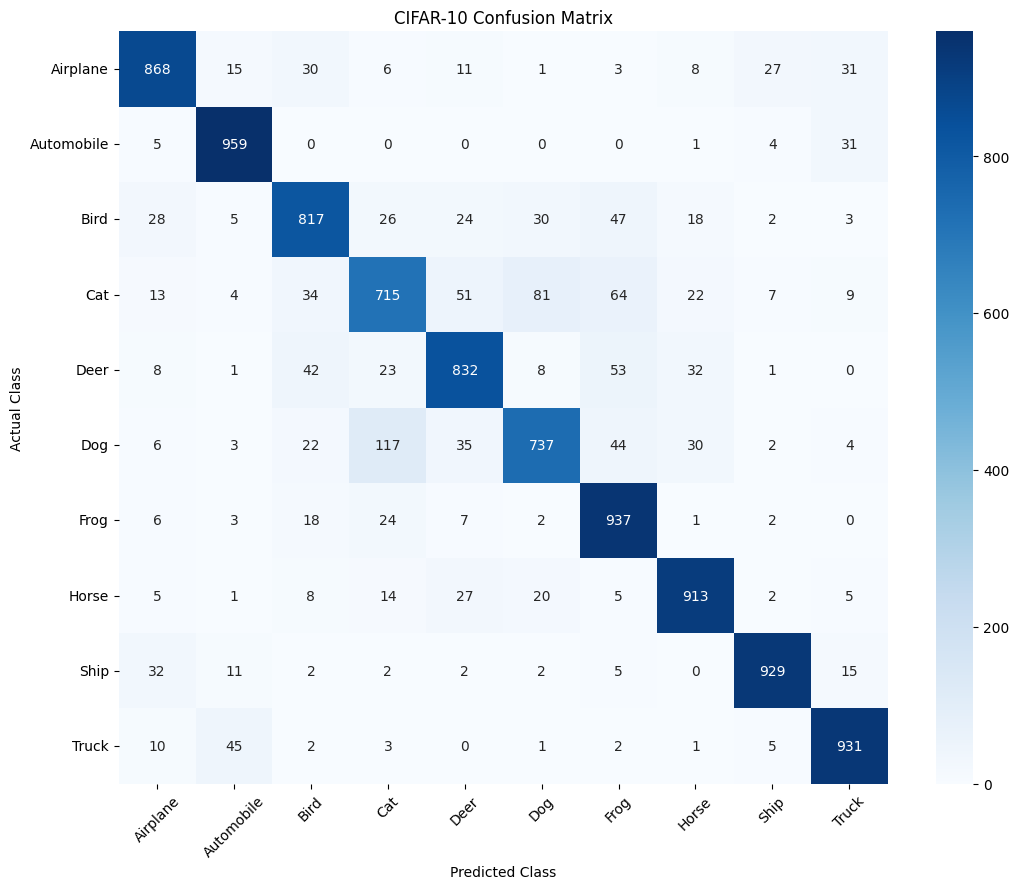

In [17]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Predict all test images
y_pred_probs = best_model.predict(x_test)

# Convert probabilities into predicted class numbers
y_pred = np.argmax(y_pred_probs, axis=1)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(11, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CIFAR-10 Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [18]:

from sklearn.metrics import classification_report

print("CIFAR-10 Classification Report")
print("------------------------------")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=class_names,
        digits=4
    )
)


CIFAR-10 Classification Report
------------------------------
              precision    recall  f1-score   support

    Airplane     0.8848    0.8680    0.8763      1000
  Automobile     0.9160    0.9590    0.9370      1000
        Bird     0.8379    0.8170    0.8273      1000
         Cat     0.7688    0.7150    0.7409      1000
        Deer     0.8413    0.8320    0.8366      1000
         Dog     0.8356    0.7370    0.7832      1000
        Frog     0.8078    0.9370    0.8676      1000
       Horse     0.8899    0.9130    0.9013      1000
        Ship     0.9470    0.9290    0.9379      1000
       Truck     0.9048    0.9310    0.9177      1000

    accuracy                         0.8638     10000
   macro avg     0.8634    0.8638    0.8626     10000
weighted avg     0.8634    0.8638    0.8626     10000



In [19]:

import os

print("Saved model path:", MODEL_PATH)

if os.path.exists(MODEL_PATH):
    print("Model saved successfully!")
    print("Model size:",
          round(os.path.getsize(MODEL_PATH) / (1024 * 1024), 2),
          "MB")
else:
    print("Model file not found!")


Saved model path: /content/drive/MyDrive/CIFAR10_Final_Project/best_cifar10_model.keras
Model saved successfully!
Model size: 16.63 MB


In [20]:

!pip -q install gradio


In [25]:

import gradio as gr
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image

# Load the trained model
best_model = tf.keras.models.load_model(MODEL_PATH)

# CIFAR-10 classes
class_names = [
    "Airplane", "Automobile", "Bird", "Cat",
    "Deer", "Dog", "Frog", "Horse",
    "Ship", "Truck"
]

# Image prediction function
def predict_image(image):

    if image is None:
        raise gr.Error("Please upload an image.")

    # Convert image to RGB
    img = Image.fromarray(
        np.asarray(image).astype("uint8")
    ).convert("RGB")

    # Resize image to 32x32
    img = img.resize((32, 32))

    # Convert to NumPy array
    img_array = np.array(img, dtype=np.float32)

    # IMPORTANT: Normalize image to 0-1
    img_array = img_array / 255.0

    # Add batch dimension
    img_array = np.expand_dims(img_array, axis=0)

    # Predict
    predictions = best_model.predict(
        img_array, verbose=0
    )[0]

    # Get predicted class
    predicted_index = np.argmax(predictions)
    predicted_class = class_names[predicted_index]

    confidence = predictions[predicted_index] * 100

    result = (
        f"Predicted Class: {predicted_class}\n"
        f"Confidence: {confidence:.2f}%"
    )

    # Confidence graph
    fig, ax = plt.subplots(figsize=(10, 5))

    ax.bar(class_names, predictions * 100)

    ax.set_title("Prediction Confidence")
    ax.set_xlabel("CIFAR-10 Classes")
    ax.set_ylabel("Confidence (%)")
    ax.set_ylim(0, 100)

    plt.xticks(rotation=45)
    plt.tight_layout()

    return np.array(img), result, fig


# Create Gradio application
demo = gr.Interface(
    fn=predict_image,

    inputs=gr.Image(
        type="numpy",
        label="Upload Image"
    ),

    outputs=[
        gr.Image(label="Processed Image"),
        gr.Textbox(label="Prediction Result"),
        gr.Plot(label="Confidence Chart")
    ],

    title="CIFAR-10 CNN Image Classifier",

    description=(
        "Upload an image to predict its class "
        "using our trained CNN model."
    )
)

# Launch application
demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9a9bfb1566d2bdc094.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [26]:

from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Predict all CIFAR-10 test images
predictions = best_model.predict(x_test, batch_size=128)

# Convert predictions into class numbers
y_pred = np.argmax(predictions, axis=1)

# Convert actual labels into class numbers
y_true = np.argmax(y_test_cat, axis=1)

# Generate classification report
print("CIFAR-10 Classification Report")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)


79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step
CIFAR-10 Classification Report
              precision    recall  f1-score   support

    Airplane       0.88      0.87      0.88      1000
  Automobile       0.92      0.96      0.94      1000
        Bird       0.84      0.82      0.83      1000
         Cat       0.77      0.71      0.74      1000
        Deer       0.84      0.83      0.84      1000
         Dog       0.84      0.74      0.78      1000
        Frog       0.81      0.94      0.87      1000
       Horse       0.89      0.91      0.90      1000
        Ship       0.95      0.93      0.94      1000
       Truck       0.90      0.93      0.92      1000

    accuracy                           0.86     10000
   macro avg       0.86      0.86      0.86     10000
weighted avg       0.86      0.86      0.86     10000



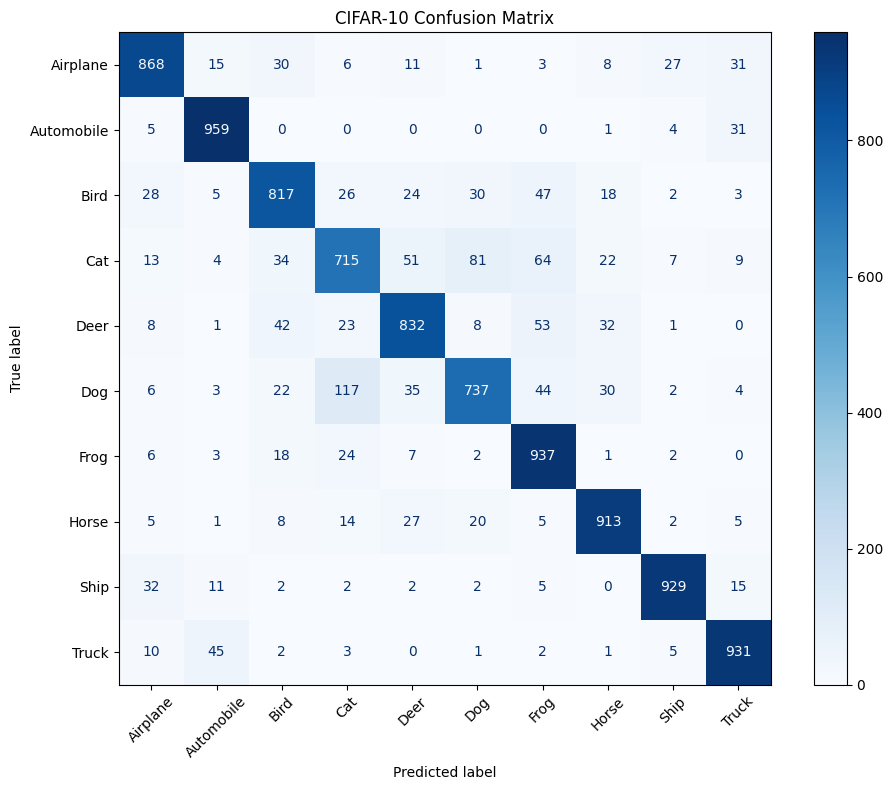

In [27]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=class_names,
    cmap="Blues",
    ax=ax
)

plt.xticks(rotation=45)
plt.title("CIFAR-10 Confusion Matrix")
plt.tight_layout()
plt.show()


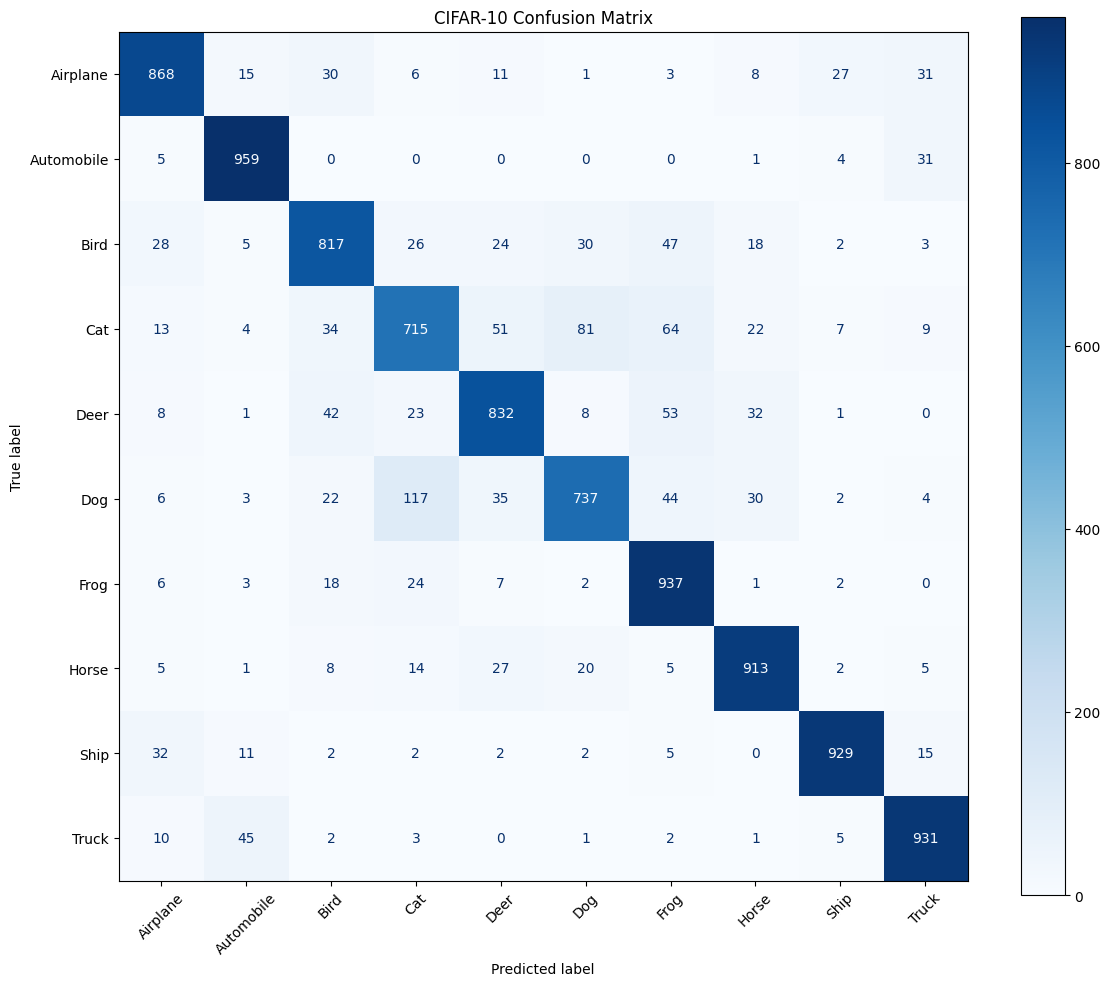

Classification report saved!
Confusion matrix saved!
All results saved to Google Drive!


In [28]:

import os
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay
)

# Create results folder in Google Drive
results_folder = "/content/drive/MyDrive/CIFAR10_Final_Project"
os.makedirs(results_folder, exist_ok=True)

# Save classification report
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names
)

report_path = os.path.join(
    results_folder,
    "classification_report.txt"
)

with open(report_path, "w") as f:
    f.write(report)

# Save confusion matrix
fig, ax = plt.subplots(figsize=(12, 10))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=class_names,
    cmap="Blues",
    ax=ax
)

plt.xticks(rotation=45)
plt.title("CIFAR-10 Confusion Matrix")
plt.tight_layout()

matrix_path = os.path.join(
    results_folder,
    "confusion_matrix.png"
)

plt.savefig(matrix_path, dpi=300)
plt.show()

print("Classification report saved!")
print("Confusion matrix saved!")
print("All results saved to Google Drive!")
